## Hồng Sen – Demo 4: Khử nhiễu (Gaussian vs. trung vị)

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

img_dir = Path("images") if Path("images").exists() else Path("../images")
img_dir.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(42)


def add_salt_pepper(img, amount):
    """Nhiễu muối-tiêu: tỉ lệ `amount` điểm ảnh bị đổi thành 0 hoặc 255 (mỗi loại một nửa)."""
    noisy = img.copy()
    u = rng.random(img.shape)
    noisy[u < amount / 2] = 0
    noisy[u > 1 - amount / 2] = 255
    return noisy


def add_gaussian_noise(img, sigma):
    """Cộng nhiễu N(0, sigma^2) rồi kẹp về [0, 255]."""
    noisy = img.astype(np.float64) + rng.normal(0, sigma, img.shape)
    return np.clip(noisy, 0, 255).astype(np.uint8)


def mse(a, b):
    return np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)


def median_filter_3x3(img):
    """Lọc trung vị 3x3, đệm viền lặp lại (giống cv2.medianBlur).
    Xếp 9 lân cận của mọi điểm ảnh thành 9 lớp rồi lấy phần tử giữa (v5) theo trục lớp."""
    H, W = img.shape
    padded = np.pad(img, 1, mode="edge")
    stack = np.stack([padded[dy:dy + H, dx:dx + W] for dy in range(3) for dx in range(3)])
    return np.sort(stack, axis=0)[4].astype(img.dtype)


K_GAUSS = np.array([[1, 2, 1],
                    [2, 4, 2],
                    [1, 2, 1]], dtype=np.float64) / 16.0


def gaussian_filter_3x3(img):
    """Lọc Gaussian 3x3 (slide 49: K_G = 1/16 [1 2 1; 2 4 2; 1 2 1]), đệm viền lặp lại."""
    H, W = img.shape
    padded = np.pad(img, 1, mode="edge").astype(np.float64)
    out = np.zeros((H, W), dtype=np.float64)
    for dy in range(3):
        for dx in range(3):
            out += K_GAUSS[dy, dx] * padded[dy:dy + H, dx:dx + W]
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

In [ ]:
# Ảnh thử trơn: mặt dốc độ sáng + một vùng sáng lồi mềm (không có cạnh gắt)
x = np.linspace(0, 1, 256)
yy, xx = np.mgrid[0:256, 0:256]
bump = 70 * np.exp(-((xx - 160) ** 2 + (yy - 100) ** 2) / (2 * 45 ** 2))
img_demo4 = np.clip(np.add.outer(x, x) * 70 + 50 + bump, 0, 255).astype(np.uint8)

# Ô đối chiếu: so với hàm của OpenCV
noisy = add_salt_pepper(img_demo4, 0.05)
err_med = np.abs(median_filter_3x3(noisy).astype(int) - cv2.medianBlur(noisy, 3).astype(int)).max()
err_gau = np.abs(gaussian_filter_3x3(noisy).astype(int) - cv2.GaussianBlur(noisy, (3, 3), 0, borderType=cv2.BORDER_REPLICATE).astype(int)).max()
print(f"median_filter_3x3   vs cv2.medianBlur  : sai khác lớn nhất = {err_med}")
print(f"gaussian_filter_3x3 vs cv2.GaussianBlur: sai khác lớn nhất = {err_gau}")

In [ ]:
# Minh họa slide 58: một hàng có điểm nhiễu 255
row = np.array([[82, 80, 255, 81, 79, 83]], dtype=np.uint8)
row3 = np.repeat(row, 3, axis=0)          # 3 hàng giống nhau để có cửa sổ 3x3
print("Hàng có nhiễu :", row[0])
print("Sau Gaussian  :", gaussian_filter_3x3(row3)[1])
print("Sau trung vị  :", median_filter_3x3(row3)[1])

In [ ]:
noisy_sp = add_salt_pepper(img_demo4, 0.10)
noisy_gs = add_gaussian_noise(img_demo4, 20)

cases = [
    ("Muối-tiêu 10%", noisy_sp),
    ("Gaussian σ=20", noisy_gs),
]

fig, axes = plt.subplots(2, 4, figsize=(14, 8.5))
for r, (name, noisy_img) in enumerate(cases):
    med = median_filter_3x3(noisy_img)
    gau = gaussian_filter_3x3(noisy_img)
    panels = [
        (img_demo4, "Ảnh gốc"),
        (noisy_img, f"{name}\nMSE={mse(img_demo4, noisy_img):.1f}"),
        (med, f"Trung vị 3×3\nMSE={mse(img_demo4, med):.1f}"),
        (gau, f"Gaussian 3×3\nMSE={mse(img_demo4, gau):.1f}"),
    ]
    for c, (im, title) in enumerate(panels):
        axes[r, c].imshow(im, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(title, fontsize=10)
        axes[r, c].axis("off")
fig.suptitle("Demo 4 – Gaussian vs. trung vị trên hai loại nhiễu", fontsize=13, fontweight="bold")
fig.tight_layout(h_pad=2.5)
fig.savefig(img_dir / "comparison_result.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
sp_levels = [0.01, 0.05, 0.10, 0.15, 0.20, 0.30]
sigmas = [5, 10, 20, 30, 40, 50]

sp_med, sp_gau = [], []
for amount in sp_levels:
    noisy_img = add_salt_pepper(img_demo4, amount)
    sp_med.append(mse(img_demo4, median_filter_3x3(noisy_img)))
    sp_gau.append(mse(img_demo4, gaussian_filter_3x3(noisy_img)))

gs_med, gs_gau = [], []
for sigma in sigmas:
    noisy_img = add_gaussian_noise(img_demo4, sigma)
    gs_med.append(mse(img_demo4, median_filter_3x3(noisy_img)))
    gs_gau.append(mse(img_demo4, gaussian_filter_3x3(noisy_img)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, title, xs, y_med, y_gau, xlabel in [
    (axes[0], "Nhiễu muối-tiêu", [a * 100 for a in sp_levels], sp_med, sp_gau, "Mật độ nhiễu (%)"),
    (axes[1], "Nhiễu Gaussian", sigmas, gs_med, gs_gau, "Độ lệch chuẩn nhiễu σ"),
]:
    ax.plot(xs, y_med, "o-", lw=2, color="#2458c6", label="Trung vị 3×3")
    ax.plot(xs, y_gau, "s-", lw=2, color="#d63d35", label="Gaussian 3×3")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("MSE (càng thấp càng tốt)")
    ax.set_xticks(xs)
    ax.set_ylim(bottom=0)
    ax.grid(True, ls="--", alpha=0.45)
    ax.legend(loc="upper left")
fig.savefig(img_dir / "MSE.png", dpi=200, bbox_inches="tight")
plt.show()

print("Muối-tiêu:")
for a, m, g in zip(sp_levels, sp_med, sp_gau):
    print(f"  {a:4.0%}: trung vị={m:8.1f}  Gaussian={g:8.1f}  -> {'trung vị' if m < g else 'Gaussian'} thắng")
print("Nhiễu Gaussian:")
for s, m, g in zip(sigmas, gs_med, gs_gau):
    print(f"  σ={s:2d}: trung vị={m:8.1f}  Gaussian={g:8.1f}  -> {'trung vị' if m < g else 'Gaussian'} thắng")

## Hồng Sen – KT2: Ngưỡng thích nghi bằng ảnh tích phân

### Có dùng AI hỗ trợ
Công cụ: Google Gemini
Mục đích: Hỗ trợ tối ưu hóa cấu trúc code khảo sát tham số r, t (Bradley) và quét tham số k (Sauvola).

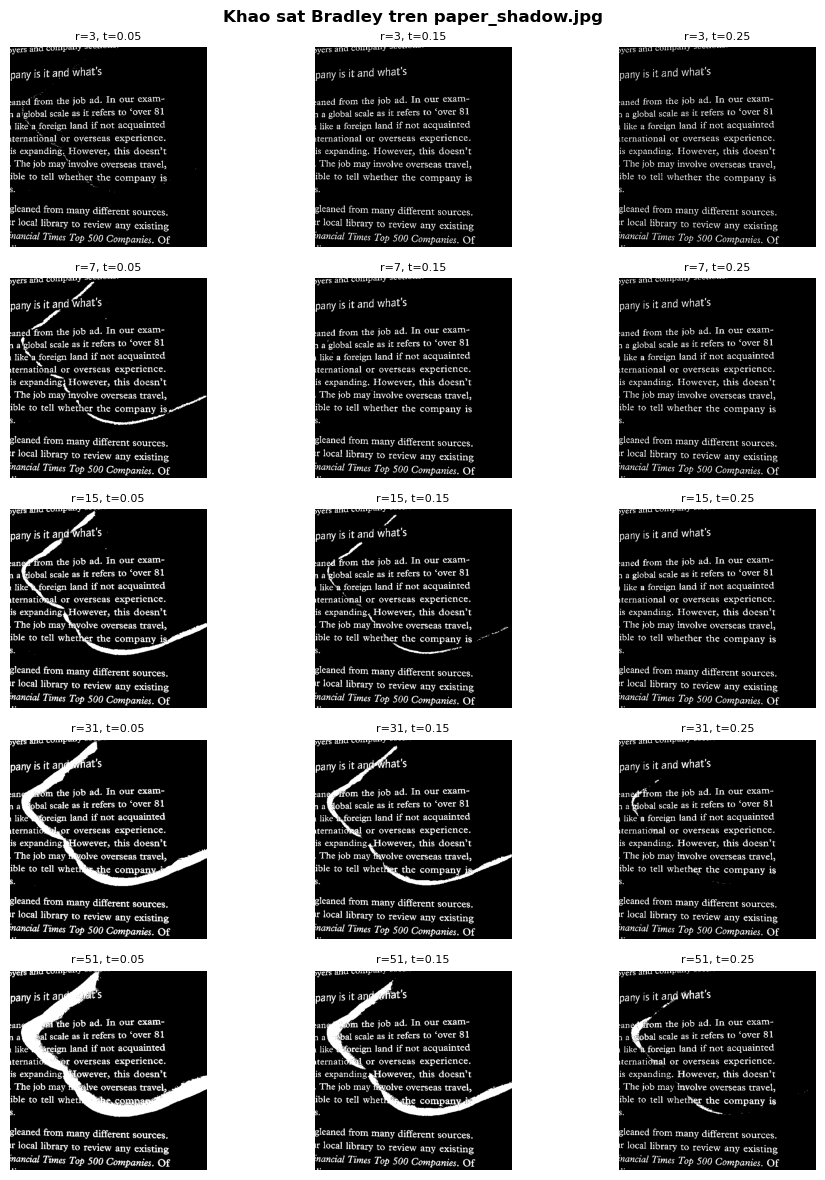

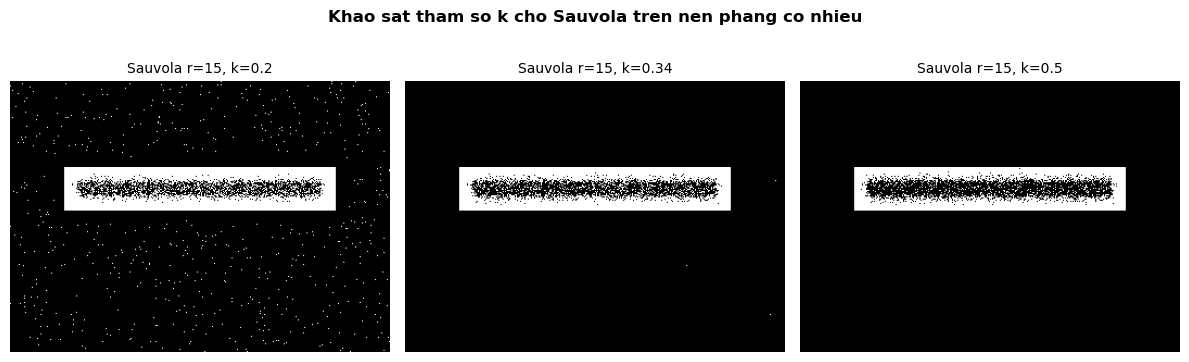

In [1]:
import cv2
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

img_dir = Path("images") if Path("images").exists() else Path("../images")
img_dir.mkdir(parents=True, exist_ok=True)

def integral_image(img):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    H, W = img.shape
    dtype = np.float64 if np.issubdtype(img.dtype, np.floating) else np.int64
    S = np.zeros((H + 1, W + 1), dtype=dtype)
    S[1:, 1:] = np.cumsum(np.cumsum(img, axis=0, dtype=dtype), axis=1, dtype=dtype)
    return S

def box_sum(S, y1, x1, y2, x2):
    """Tổng vùng [y1..y2, x1..x2] (bao gồm biên) theo ảnh tích phân S có đệm viền.
    Các chỉ số có thể là số nguyên hoặc mảng numpy (vectơ hóa)."""
    return S[y2 + 1, x2 + 1] - S[y1, x2 + 1] - S[y2 + 1, x1] + S[y1, x1]

def local_mean_std(img, radius):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    H, W = img.shape
    w = 2 * radius + 1
    w2 = w * w
    padded = np.pad(img, radius, mode='edge').astype(np.int64)
    S1 = integral_image(padded)
    S2 = integral_image(padded * padded)
    # Cửa sổ quanh điểm (y, x) của ảnh gốc là [y..y+2r, x..x+2r] trên ảnh đã đệm
    ys = np.arange(H)[:, None]
    xs = np.arange(W)[None, :]
    sum1 = box_sum(S1, ys, xs, ys + 2 * radius, xs + 2 * radius).astype(np.float64)
    sum2 = box_sum(S2, ys, xs, ys + 2 * radius, xs + 2 * radius).astype(np.float64)
    mean = sum1 / w2
    var = (sum2 / w2) - (mean ** 2)
    var = np.maximum(var, 0.0)
    std = np.sqrt(var)
    return mean, std

def adaptive_threshold(img, radius=15, method='bradley', t=0.15, k=0.34, R=128.0):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    mean, std = local_mean_std(img, radius)
    img_f = img.astype(np.float64)
    if method.lower() == 'bradley':
        T = mean * (1.0 - t)
    elif method.lower() == 'sauvola':
        T = mean * (1.0 + k * ((std / R) - 1.0))
    else:
        raise ValueError("Phương pháp không hợp lệ!")
    binary = np.where(img_f < T, 255, 0).astype(np.uint8)
    return binary

# Ô đối chiếu: so với cv2.integral
_test = np.random.randint(0, 256, (60, 80), dtype=np.uint8)
print("integral_image == cv2.integral:", np.array_equal(integral_image(_test), cv2.integral(_test).astype(np.int64)))
_m, _ = local_mean_std(_test, 3)
print("local_mean sai khác lớn nhất so với cv2.blur:",
      np.abs(_m - cv2.blur(_test.astype(np.float64), (7, 7), borderType=cv2.BORDER_REPLICATE)).max())

# 1. Khảo sát Bradley trên ảnh bóng mờ (paper_shadow.jpg) từ repo
shadow_path = img_dir / "paper_shadow.jpg"
if shadow_path.exists():
    shadow_img = cv2.imread(str(shadow_path), cv2.IMREAD_GRAYSCALE)
    radii_sweep = [3, 7, 15, 31, 51]
    t_sweep = [0.05, 0.15, 0.25]
    
    fig, axes = plt.subplots(len(radii_sweep), len(t_sweep), figsize=(10, 12))
    for i, r in enumerate(radii_sweep):
        for j, t_val in enumerate(t_sweep):
            res = adaptive_threshold(shadow_img, radius=r, method='bradley', t=t_val)
            axes[i, j].imshow(res, cmap='gray', vmin=0, vmax=255)
            axes[i, j].set_title(f"r={r}, t={t_val}", fontsize=8)
            axes[i, j].axis('off')
    plt.suptitle("Khao sat Bradley tren paper_shadow.jpg", fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

# 2. Tạo ảnh nền phẳng rộng có nhiễu và quét tham số k cho Sauvola (>= 3 giá trị)
np.random.seed(42)
flat_img = np.ones((250, 350), dtype=np.uint8) * 200
flat_img[80:120, 50:300] = 40
noise = np.random.normal(0, 15, flat_img.shape).astype(np.int32)
flat_noisy = np.clip(flat_img.astype(np.int32) + noise, 0, 255).astype(np.uint8)

k_sweep = [0.2, 0.34, 0.5]
fig, axes = plt.subplots(1, len(k_sweep), figsize=(12, 4))
for j, k_val in enumerate(k_sweep):
    res_s = adaptive_threshold(flat_noisy, radius=15, method='sauvola', k=k_val)
    axes[j].imshow(res_s, cmap='gray', vmin=0, vmax=255)
    axes[j].set_title(f"Sauvola r=15, k={k_val}", fontsize=10)
    axes[j].axis('off')
plt.suptitle("Khao sat tham so k cho Sauvola tren nen phang co nhieu", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Có dùng AI hỗ trợ
Công cụ: Google Gemini
Mục đích: Hỗ trợ so sánh trực quan 4 phương pháp ngưỡng hóa trên ảnh bóng mờ và ảnh nền phẳng có nhiễu.

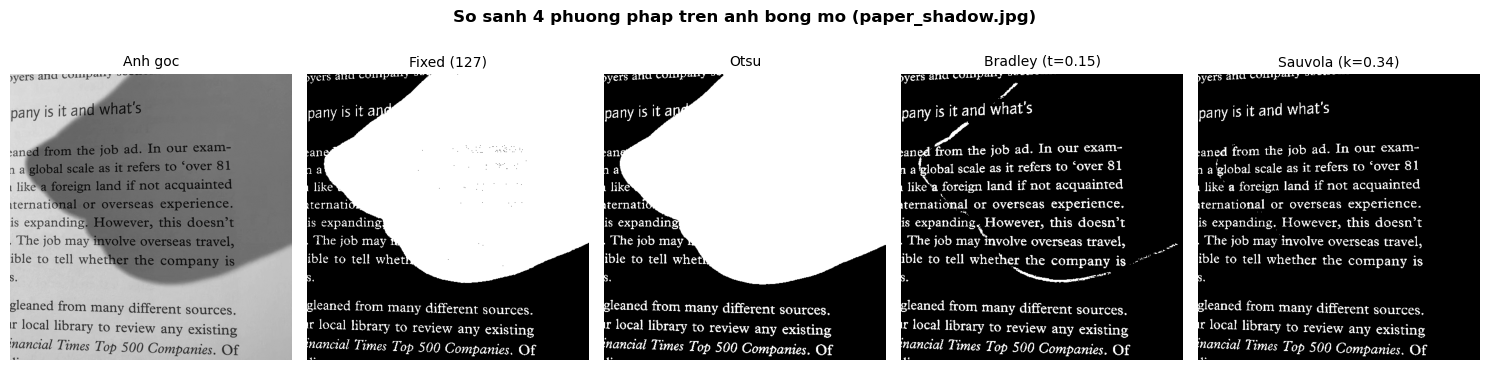

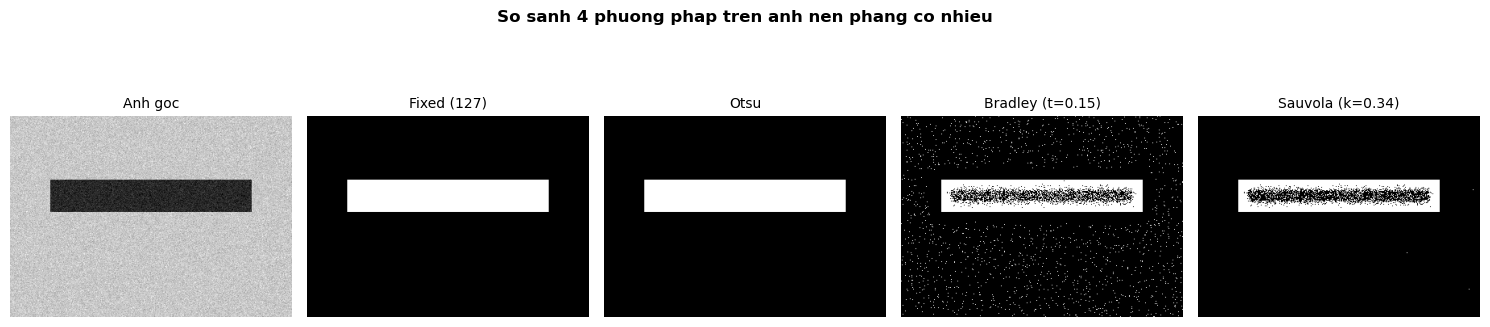

In [2]:
def manual_fixed_threshold(img, thresh=127):
    return np.where(img.astype(np.float64) < thresh, 255, 0).astype(np.uint8)

def manual_otsu_threshold(img):
    _, res = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return res

methods_titles = ["Anh goc", "Fixed (127)", "Otsu", "Bradley (t=0.15)", "Sauvola (k=0.34)"]

# A. So sánh 4 phương pháp trên ảnh bóng mờ (paper_shadow.jpg)
if shadow_path.exists():
    s_img = cv2.imread(str(shadow_path), cv2.IMREAD_GRAYSCALE)
    images_shadow = [
        s_img,
        manual_fixed_threshold(s_img, 127),
        manual_otsu_threshold(s_img),
        adaptive_threshold(s_img, radius=15, method='bradley', t=0.15),
        adaptive_threshold(s_img, radius=15, method='sauvola', k=0.34)
    ]
    
    fig, axes = plt.subplots(1, 5, figsize=(15, 4))
    for ax, img_item, title in zip(axes, images_shadow, methods_titles):
        ax.imshow(img_item, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.suptitle("So sanh 4 phuong phap tren anh bong mo (paper_shadow.jpg)", fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

# B. So sánh 4 phương pháp trên ảnh nền phẳng có nhiễu
images_flat = [
    flat_noisy,
    manual_fixed_threshold(flat_noisy, 127),
    manual_otsu_threshold(flat_noisy),
    adaptive_threshold(flat_noisy, radius=15, method='bradley', t=0.15),
    adaptive_threshold(flat_noisy, radius=15, method='sauvola', k=0.34)
]

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for ax, img_item, title in zip(axes, images_flat, methods_titles):
    ax.imshow(img_item, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.axis('off')
plt.suptitle("So sanh 4 phuong phap tren anh nen phang co nhieu", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Có dùng AI hỗ trợ
Công cụ: Google Gemini
Mục đích: Hỗ trợ cấu hình biểu đồ độ phức tạp thời gian chạy thang log.

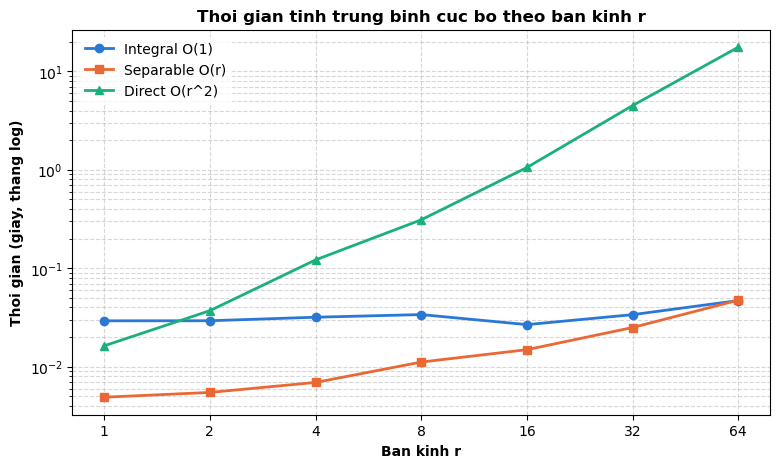

In [3]:
import time

def separable_filter_1d_numpy(img, radius):
    w = 2 * radius + 1
    H, W = img.shape
    padded = np.pad(img, radius, mode='edge').astype(np.float64)
    rows = np.zeros((H + 2 * radius, W), dtype=np.float64)
    for dx in range(w):
        rows += padded[:, dx:dx + W]
    out = np.zeros((H, W), dtype=np.float64)
    for dy in range(w):
        out += rows[dy:dy + H, :]
    return out / (w * w)

def box_filter_direct(img, kernel):
    h_k, w_k = kernel.shape
    pad_h, pad_w = h_k // 2, w_k // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge').astype(np.float64)
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for dy in range(h_k):
        for dx in range(w_k):
            out += kernel[dy, dx] * padded[dy:dy + H, dx:dx + W]
    return out

def bench(fn, repeat=3):
    best = float('inf')
    for _ in range(repeat):
        start = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - start)
    return best

radii_list = [1, 2, 4, 8, 16, 32, 64]
dummy_img = np.random.randint(0, 256, (512, 512), dtype=np.uint8)

t_integral, t_separable, t_direct = [], [], []
for r in radii_list:
    w = 2 * r + 1
    kernel_2d = np.ones((w, w), dtype=np.float64) / (w * w)
    t_integral.append(bench(lambda: local_mean_std(dummy_img, radius=r), 3))
    t_separable.append(bench(lambda: separable_filter_1d_numpy(dummy_img, radius=r), 3))
    t_direct.append(bench(lambda: box_filter_direct(dummy_img, kernel_2d), 1 if r > 16 else 2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(radii_list, t_integral, marker='o', label='Integral O(1)', color='#2a78d6', linewidth=2)
ax.plot(radii_list, t_separable, marker='s', label='Separable O(r)', color='#eb6834', linewidth=2)
ax.plot(radii_list, t_direct, marker='^', label='Direct O(r^2)', color='#1baf7a', linewidth=2)

ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_xticks(radii_list)
ax.set_xticklabels([str(r) for r in radii_list])
ax.set_xlabel('Ban kinh r', fontweight='bold')
ax.set_ylabel('Thoi gian (giay, thang log)', fontweight='bold')
ax.set_title('Thoi gian tinh trung binh cuc bo theo ban kinh r', fontweight='bold')
ax.legend(loc="upper left", frameon=True, facecolor='white', edgecolor='none')
ax.grid(True, which="both", ls="--", alpha=0.5)

chart_path = img_dir / "time_complexity.png"
fig.savefig(str(chart_path), dpi=300, bbox_inches='tight')
plt.show()